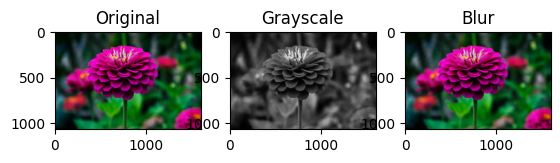

In [20]:
!pip install opencv-python matplotlib
import cv2
import matplotlib.pyplot as plt

img = cv2.imread("/flower.jpeg")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
resize = cv2.resize(img, (300, 300))
blur = cv2.GaussianBlur(img, (5, 5), 0)

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original")

plt.subplot(1, 3, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(blur, cv2.COLOR_BGR2RGB))
plt.title("Blur")

plt.show()

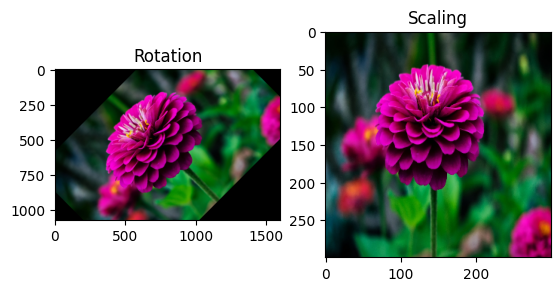

In [21]:
!pip install opencv-python matplotlib

import cv2
import matplotlib.pyplot as plt

img = cv2.imread("/flower.jpeg")

rows, cols = img.shape[:2]

# Translation
M = cv2.getRotationMatrix2D((cols/2, rows/2), 45, 1)
rotate = cv2.warpAffine(img, M, (cols, rows))

# Resize
resize = cv2.resize(img, (300, 300))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(rotate, cv2.COLOR_BGR2RGB))
plt.title("Rotation")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(resize, cv2.COLOR_BGR2RGB))
plt.title("Scaling")

plt.show()

In [22]:
!pip install opencv-python numpy

import cv2
import numpy as np

src = np.float32([
    [0, 0], [100, 0],
    [100, 100], [0, 100]
])

dst = np.float32([
    [10, 20], [120, 10],
    [110, 120], [20, 110]
])

H, status = cv2.findHomography(src, dst)

print("Homography Matrix:")
print(H)

Homography Matrix:
[[ 8.60e-01  1.40e-01  1.00e+01]
 [-1.20e-01  1.12e+00  2.00e+01]
 [-2.00e-03  2.00e-03  1.00e+00]]


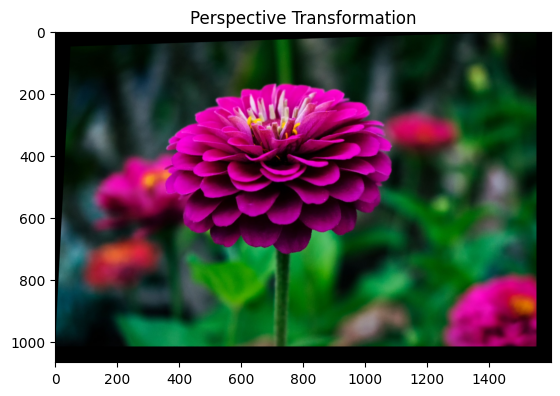

In [23]:
!pip install opencv-python numpy matplotlib

import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("/flower.jpeg")

h, w = img.shape[:2]

src = np.float32([
    [0, 0], [w, 0],
    [w, h], [0, h]
])

dst = np.float32([
    [50, 50], [w-50, 0],
    [w-50, h-50], [0, h-50]
])

M = cv2.getPerspectiveTransform(src, dst)

result = cv2.warpPerspective(img, M, (w, h))

plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Perspective Transformation")
plt.show()

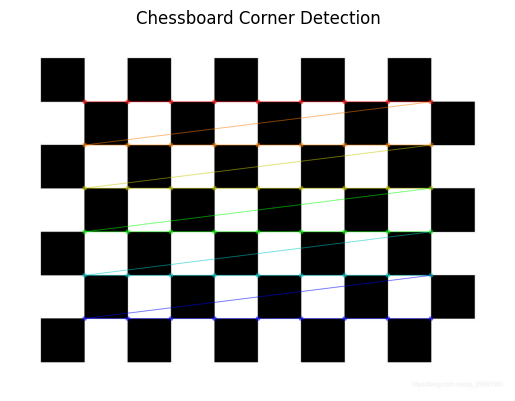

Camera Matrix:
[[9.79891741e+04 0.00000000e+00 6.32388469e+02]
 [0.00000000e+00 9.78357010e+04 7.80786297e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
Distortion:
[[-1.58085894e+01 -1.83688735e+05 -8.97657926e-02 -2.02541701e-03
  -1.75920747e-06]]
Calibration Error:
0.23789467355625346


In [24]:
!pip install opencv-python numpy matplotlib

import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("/cheese.jpeg")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

ret, corners = cv2.findChessboardCorners(gray, (9, 6), None)

cv2.drawChessboardCorners(img, (9, 6), corners, ret)

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Chessboard Corner Detection")
plt.axis("off")
plt.show()

objp = np.zeros((54, 3), np.float32)
objp[:, :2] = np.mgrid[0:9, 0:6].T.reshape(-1, 2)

ret, matrix, dist, rvecs, tvecs = cv2.calibrateCamera(
    [objp], [corners], gray.shape[::-1], None, None
)

print("Camera Matrix:")
print(matrix)

print("Distortion:")
print(dist)

print("Calibration Error:")
print(ret)

In [25]:
!pip install opencv-python numpy
import cv2
import numpy as np

p1 = np.float32([
    [100, 100], [200, 150],
    [300, 100], [400, 250],
    [150, 300], [350, 350],
    [250, 400], [450, 100]
])

p2 = np.float32([
    [120, 110], [220, 180],
    [310, 130], [420, 270],
    [170, 320], [370, 380],
    [270, 430], [470, 130]
])

F, mask = cv2.findFundamentalMat(
    p1, p2, cv2.FM_8POINT
)

print("Fundamental Matrix:")
print(F)


Fundamental Matrix:
[[ 1.49539119e-05  9.40948770e-05 -3.81340375e-02]
 [-9.17197315e-05 -3.76876159e-07  3.70561706e-02]
 [ 3.06090617e-02 -3.90392430e-02  1.00000000e+00]]


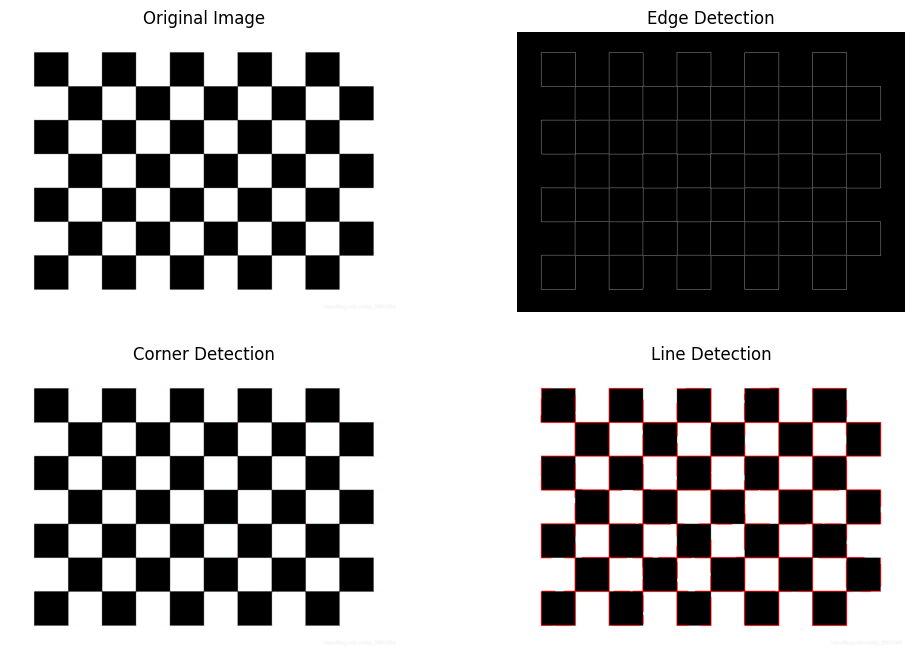

In [26]:
!pip install opencv-python numpy matplotlib
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("/cheese.jpeg")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Edge Detection
edges = cv2.Canny(gray, 100, 200)

# Corner Detection
corners = cv2.cornerHarris(np.float32(gray), 2, 3, 0.04)
corner_img = img.copy()
corner_img[corners > 0.01 * corners.max()] = [0, 0, 255]

# Line Detection
lines = cv2.HoughLinesP(edges, 1, np.pi/180, 30,
                        minLineLength=20, maxLineGap=15)

line_img = img.copy()

for line in (lines if lines is not None else []):
    x1, y1, x2, y2 = np.array(line).reshape(-1)
    cv2.line(line_img, (x1, y1), (x2, y2), (0, 0, 255), 2)

# Display Results
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(edges, cmap="gray")
plt.title("Edge Detection")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(cv2.cvtColor(corner_img, cv2.COLOR_BGR2RGB))
plt.title("Corner Detection")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(cv2.cvtColor(line_img, cv2.COLOR_BGR2RGB))
plt.title("Line Detection")
plt.axis("off")

plt.show()

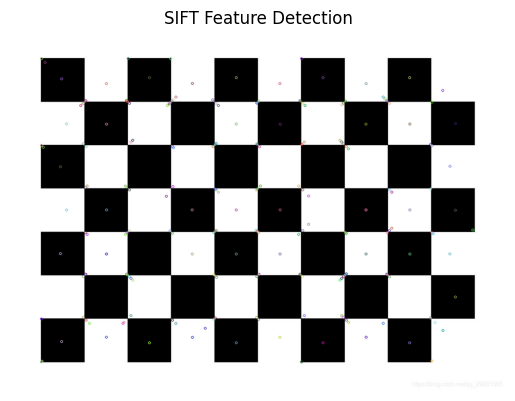

Number of Keypoints: 447


In [31]:
!pip install opencv-python matplotlib

import cv2
import matplotlib.pyplot as plt

img = cv2.imread("/cheese.jpeg")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

sift = cv2.SIFT_create()
keypoints, descriptors = sift.detectAndCompute(gray, None)

result = cv2.drawKeypoints(img, keypoints, None)

plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("SIFT Feature Detection")
plt.axis("off")
plt.show()

print("Number of Keypoints:", len(keypoints))

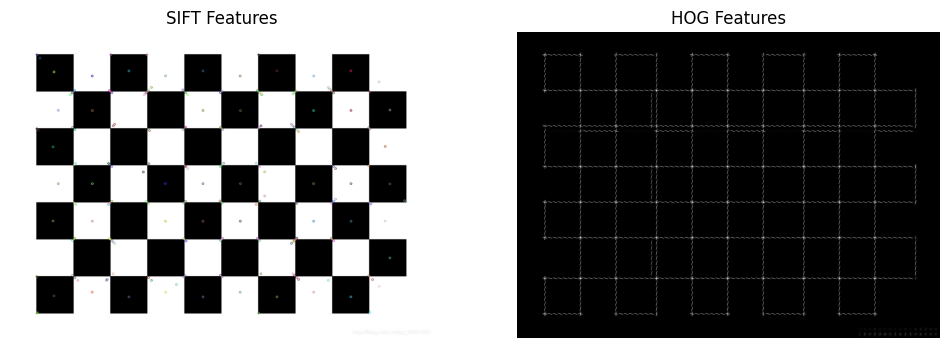

SIFT Keypoints: 447
HOG Feature Shape: (39840,)


In [32]:
!pip install opencv-python matplotlib numpy scikit-image
import cv2
import matplotlib.pyplot as plt
from skimage.feature import hog
from skimage import exposure

img = cv2.imread("/cheese.jpeg")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# SIFT Feature Detection
sift = cv2.SIFT_create()
keypoints, descriptors = sift.detectAndCompute(gray, None)
sift_img = cv2.drawKeypoints(img, keypoints, None)

# HOG Feature Extraction and Visualization using skimage
features, hog_image = hog(gray, orientations=8, pixels_per_cell=(16, 16),
                          cells_per_block=(1, 1), visualize=True)

# Rescale histogram for better display
hog_image_rescaled = exposure.rescale_intensity(hog_image, in_range=(0, 10))

# Display Results
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(sift_img, cv2.COLOR_BGR2RGB))
plt.title("SIFT Features")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(hog_image_rescaled, cmap="gray")
plt.title("HOG Features")
plt.axis("off")

plt.show()

print("SIFT Keypoints:", len(keypoints))
print("HOG Feature Shape:", features.shape)